In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tools.eval_measures  import rmse

## **Exercise: Simple Linear Regression**

Dataset: mpg

1. Analize data 
    - feature: horsepower
    - target: mpg
    <br><br>
2. Apply linear regression
3. Interpret f-test and t-test
4. Interpret the result
5. merge y_predict & residual
6. calculate RMSE
7. please explore other model approach to hit lower RMSE from number 6! (bonus)

In [44]:
df_ = sns.load_dataset('mpg')
df_

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger


In [52]:
df = df_.dropna().reset_index()
df

,index,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...,...,...
387,393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
388,394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
389,395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
390,396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger


In [54]:
df.isna().sum()

index           0
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

In [55]:
df[['horsepower','mpg']].describe()

,horsepower,mpg
count,392.000000,392.000000
mean,104.469388,23.445918
std,38.491160,7.805007
min,46.000000,9.000000
25%,75.000000,17.000000
50%,93.500000,22.750000
75%,126.000000,29.000000
max,230.000000,46.600000


In [56]:
df[['horsepower','mpg']].corr()

,horsepower,mpg
horsepower,1.000000,-0.778427
mpg,-0.778427,1.000000


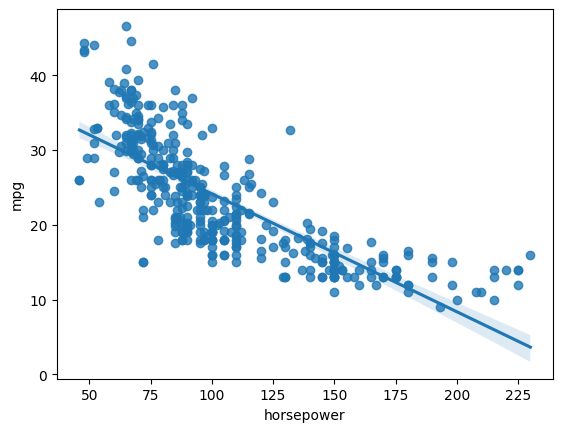

In [57]:
sns.regplot(data=df, x='horsepower', y='mpg')
plt.show()

In [58]:
Y = df['mpg']
x = sm.add_constant(df['horsepower'])
display(Y, x)

0      18.0
1      15.0
2      18.0
3      16.0
4      17.0
       ... 
387    27.0
388    44.0
389    32.0
390    28.0
391    31.0
Name: mpg, Length: 392, dtype: float64

,const,horsepower
0,1.0,130.0
1,1.0,165.0
2,1.0,150.0
3,1.0,150.0
4,1.0,140.0
...,...,...
387,1.0,86.0
388,1.0,52.0
389,1.0,84.0
390,1.0,79.0


In [59]:
sm_lm = sm.OLS(Y,x)
result = sm_lm.fit()

In [60]:
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     599.7
Date:                Tue, 28 May 2024   Prob (F-statistic):           7.03e-81
Time:                        13:20:21   Log-Likelihood:                -1178.7
No. Observations:                 392   AIC:                             2361.
Df Residuals:                     390   BIC:                             2369.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         39.9359      0.717     55.660      0.0

Y = 39.9359 - 0.1578x

F-Test:
B1 is below than 0.05, indicate we have enough evidence to reject horsepower have no affect for mpg. Thus, the conclusion, horsepower affect the mpg.

T-Test(Partial Test):
1. B0: P-value < 0.05, the model needs B0.
2. B1: P-value < 0.05, the model needs B1.

Parameter Estimate:
B0 = 39.5359: this is the condition where horsepower equal to zero. But the domain for horsepower equal to zero is not exists. This is no need to be interpreted because (from the domain), there is no possibility that horsepower is zero (x=0).
B1 = -0.1578: When the horsepower increase by 1, the mpg will be decrease about 0.1578. Or, when horsepower increase by 10, the mpg will decrease by 1.578. (This interpretation only when the horsepower fall berween 46 and 230)

R-Square: 60.6%, the model can explain 60.6 variation of tips.

In [61]:
y_predict = result.predict()
y_predict = pd.DataFrame(data=y_predict, columns=['prediction'])
y_predict

,prediction
0,19.416046
1,13.891480
2,16.259151
3,16.259151
4,17.837598
...,...
387,26.361214
388,31.727935
389,26.676903
390,27.466127


In [62]:
df['y_pred'] = y_predict
df

,index,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name,y_pred
0,0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu,19.416046
1,1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320,13.891480
2,2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite,16.259151
3,3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst,16.259151
4,4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino,17.837598
...,...,...,...,...,...,...,...,...,...,...,...
387,393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl,26.361214
388,394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup,31.727935
389,395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage,26.676903
390,396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger,27.466127


In [63]:
df['residual'] = df['mpg'] - df['y_pred']

In [66]:
np.sqrt(sum(pow(df['residual'],2))/len(df))

4.893226230065713

In [67]:
rmse = rmse(df['mpg'], df['y_pred'])
rmse

4.893226230065713

<Axes: xlabel='horsepower', ylabel='mpg'>

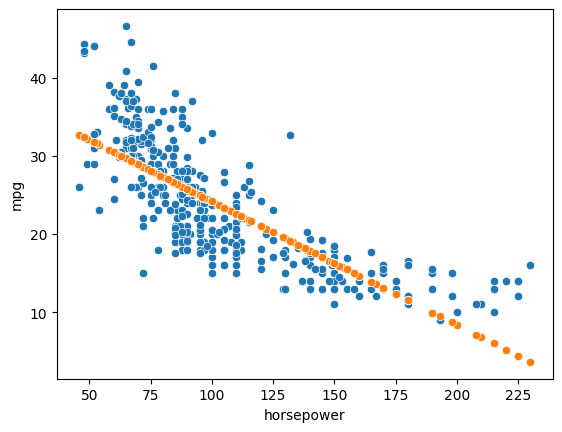

In [69]:
sns.scatterplot(data=df, x='horsepower', y='mpg')
sns.scatterplot(data=df, x='horsepower', y='y_pred')